In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from wordcloud import WordCloud

In [25]:
df = pd.read_csv("/kaggle/input/datasets/kritikamagnani8/flipkart-data/flipkart_product.csv", encoding="latin1", on_bad_lines='skip')

df.head()

,ProductName,Price,Rate,Review,Summary
0,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",5,Super!,Great cooler.. excellent air flow and for this...
1,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",5,Awesome,Best budget 2 fit cooler. Nice cooling
2,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",3,Fair,The quality is good but the power of air is de...
3,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",1,Useless product,Very bad product it's a only a fan
4,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",3,Fair,Ok ok product


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 189874 entries, 0 to 189873
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   ProductName  189874 non-null  object
 1   Price        189873 non-null  object
 2   Rate         189873 non-null  object
 3   Review       189870 non-null  object
 4   Summary      189860 non-null  object
dtypes: object(5)
memory usage: 7.2+ MB


In [27]:
df = df.dropna(subset=["Review","Rate"])
df = df.drop_duplicates(subset=["ProductName","Review","Summary"])

In [28]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z]', ' ', text)
    words = text.split()
    return " ".join(words)

df["text"] = df["Review"].astype(str) + " " + df["Summary"].fillna("").astype(str)
df["clean_review"] = df["text"].apply(clean_text)

In [29]:
df[["Review","clean_review"]].head()

,Review,clean_review
0,Super!,super great cooler excellent air flow and for ...
1,Awesome,awesome best budget fit cooler nice cooling
2,Fair,fair the quality is good but the power of air ...
3,Useless product,useless product very bad product it s a only a...
4,Fair,fair ok ok product


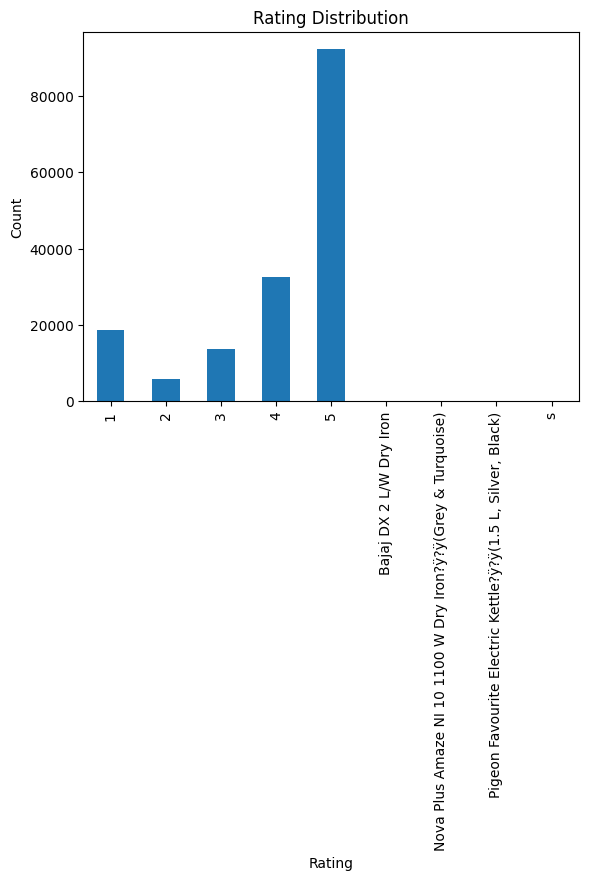

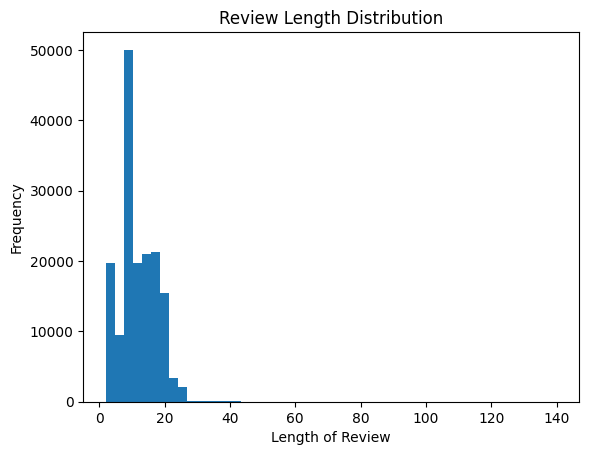

In [30]:
#Rating Distribution (1-5 stars)
import matplotlib.pyplot as plt

plt.figure()
df["Rate"].value_counts().sort_index().plot(kind="bar")

plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")

plt.show()

#Review Length Distribution (Short vs Long reviews)
df["review_length"] = df["Review"].astype(str).apply(len)

plt.figure()

df["review_length"].plot(kind="hist", bins=50)

plt.title("Review Length Distribution")
plt.xlabel("Length of Review")
plt.ylabel("Frequency")

plt.show()



In [31]:
def sentiment_label(r):

    # r is already a float at this point after the cleaning steps below
    if r >= 4:
        return "Positive"
    elif r == 3:
        return "Neutral"
    else:
        return "Negative"

# Convert 'Rate' column to numeric, coercing errors to NaN
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')
# Drop rows where 'Rate' is NaN (these are the non-numeric values we couldn't convert)
df.dropna(subset=['Rate'], inplace=True)
# Ensure 'Rate' is float type for consistency in the sentiment_label function
df['Rate'] = df['Rate'].astype(float)

df["Sentiment"] = df["Rate"].apply(sentiment_label)

In [32]:
df["Sentiment"].value_counts()

Sentiment
Positive    124708
Negative     24485
Neutral      13575
Name: count, dtype: int64

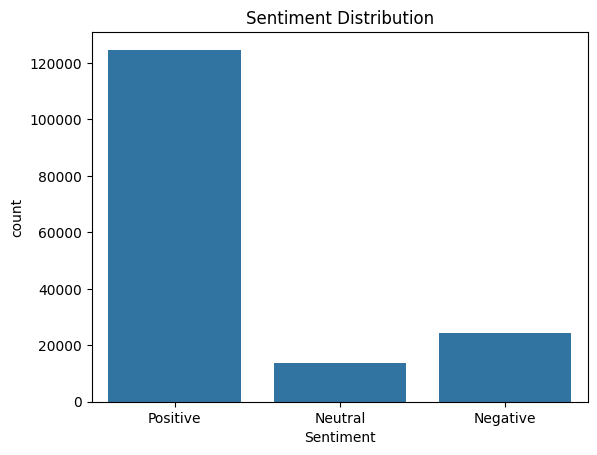

In [33]:
sns.countplot(x="Sentiment", data=df)

plt.title("Sentiment Distribution")

plt.show()

In [34]:
vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), sublinear_tf=True)

X = vectorizer.fit_transform(df["clean_review"])

y = df["Sentiment"]

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [36]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(n_jobs=-1, random_state=42),
    "SVM": LinearSVC(class_weight="balanced")
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(name, "Accuracy:", acc)

Logistic Regression Accuracy: 0.9676844627388339
Naive Bayes Accuracy: 0.9542298949437857
Random Forest Accuracy: 0.9740431283406034
SVM Accuracy: 0.9772378202371444


In [37]:
best_model = LinearSVC(class_weight="balanced")

best_model.fit(X_train, y_train)

preds = best_model.predict(X_test)

print(classification_report(y_test, preds))

              precision    recall  f1-score   support

    Negative       0.97      0.97      0.97      4897
     Neutral       0.89      0.87      0.88      2715
    Positive       0.99      0.99      0.99     24942

    accuracy                           0.98     32554
   macro avg       0.95      0.95      0.95     32554
weighted avg       0.98      0.98      0.98     32554



In [38]:
def predict_sentiment(review):

    review = clean_text(review)

    vector = vectorizer.transform([review])

    prediction = best_model.predict(vector)

    return prediction[0]

In [39]:
predict_sentiment("This product quality is amazing")

'Positive'

In [40]:
positive_products = df[df["Sentiment"]=="Positive"]

top_positive = positive_products["ProductName"].value_counts().head(10)

print(top_positive)

ProductName
cello Pack of 18 Opalware Cello Dazzle Lush Fiesta Opalware Dinner Set, 18 Pieces Dinner SetÂ Â (White, Microwave Safe)           5716
MILTON Thermosteel Flip Lid 500 ml FlaskÂ Â (Pack of 1, Silver, Steel)                                                            5029
Home Sizzler 153 cm (5.02 ft) Polyester Room Darkening Window Curtain (Pack Of 2)Â Â (Floral, Brown)                              2761
Mi 5A 80 cm (32 inch) HD Ready LED Smart Android TV with Dolby Audio (2022 Model)                                                 1734
Singer FM 1409 Electric Sewing MachineÂ Â ( Built-in Stitches 9)                                                                  1557
Canon EOS 3000D DSLR Camera 1 Camera Body, 18 - 55 mm LensÂ Â (Black)                                                             1543
CMerchants Multi Organiser BLue-4 Book Shelf Metal Open Book ShelfÂ Â (Finish Color - BLUE, DIY(Do-It-Yourself))                  1514
Cosito 144 TC Cotton Double Floral Flat Bed

In [41]:
negative_products = df[df["Sentiment"]=="Negative"]

top_negative = negative_products["ProductName"].value_counts().head(10)

print(top_negative)

ProductName
cello Pack of 18 Opalware Cello Dazzle Lush Fiesta Opalware Dinner Set, 18 Pieces Dinner SetÂ Â (White, Microwave Safe)    568
MILTON Thermosteel Flip Lid 500 ml FlaskÂ Â (Pack of 1, Silver, Steel)                                                     490
Men Graphic Print Round Neck Black T-Shirt                                                                                 370
Men Cargos                                                                                                                 359
Kadio Analog 20 cm X 20 cm Wall ClockÂ Â (Beige, With Glass, Standard)                                                     351
Pigeon Favourite Electric Kettle?ÿ?ÿ(1.5 L, Silver, Black)                                                                 341
POCO C31 (Royal Blue, 64 GB)?ÿ?ÿ(4 GB RAM)                                                                                 310
Google Nest Mini (2nd Gen) with Google Assistant Smart Speaker?ÿ?ÿ(Chalk)                          

In [42]:
# put directly after cell 4, then delete the old cells 18 and 19
df["clean_review"] = df["clean_review"].fillna("")
df = df[df["clean_review"].str.strip() != ""]

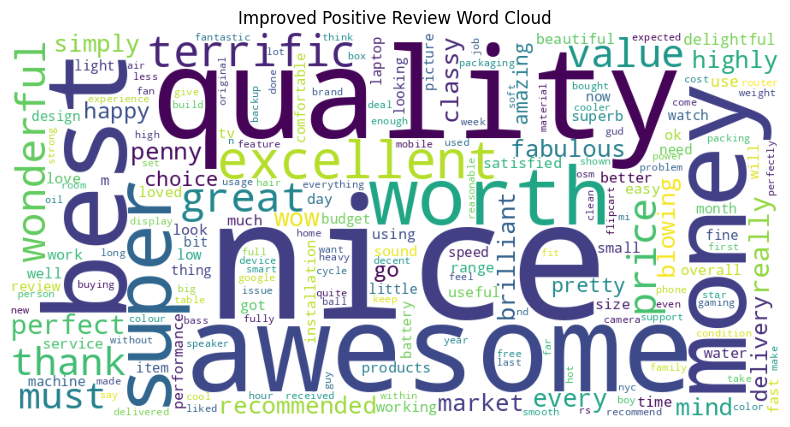

In [49]:
from wordcloud import WordCloud, STOPWORDS

positive_reviews = df[df["Sentiment"] == "Positive"]["clean_review"].dropna()
text = " ".join(positive_reviews)

# keep negations attached: "not bad" -> "not_bad", "no problem" -> "not_problem"
text = re.sub(r"\b(don|doesn|didn|isn|wasn|can|won|couldn|wouldn)\s+t\s+(\w+)", r"not_\2", text)
text = re.sub(r"\b(not|no|never)\s+(\w+)", r"not_\2", text)

custom_stopwords = set(STOPWORDS)
custom_stopwords.update([
    "product", "buy", "purchase", "purchased", "amazon", "flipkart",
    "nan", "t", "s", "don", "u", "one", "good"   # "good" removed so other words show
])

wordcloud = WordCloud(
    width=900,
    height=450,
    background_color="white",
    stopwords=custom_stopwords,
    collocations=False
).generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud)
plt.axis("off")
plt.title("Improved Positive Review Word Cloud")
plt.show()

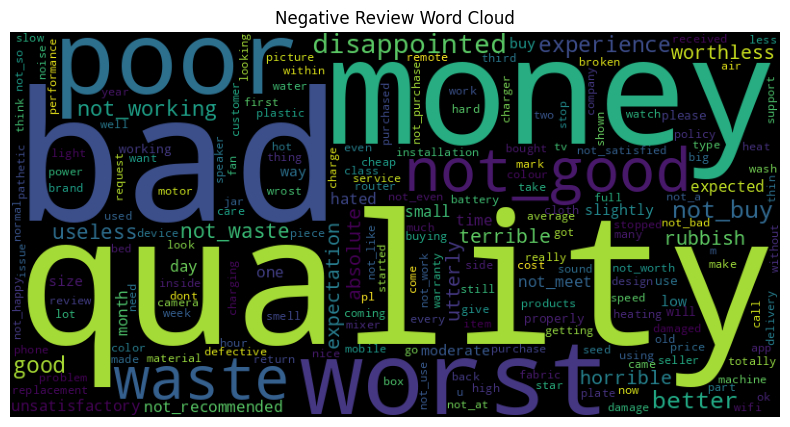

In [48]:
from wordcloud import WordCloud, STOPWORDS

negative_reviews = df[df["Sentiment"] == "Negative"]["clean_review"].dropna()
text = " ".join(negative_reviews)

# "don t buy" -> "not_buy", "not good" -> "not_good"
text = re.sub(r"\b(don|doesn|didn|isn|wasn|can|won|couldn|wouldn)\s+t\s+(\w+)", r"not_\2", text)
text = re.sub(r"\b(not|no|never)\s+(\w+)", r"not_\2", text)

stop = set(STOPWORDS)
stop.update(["nan", "t", "s", "don", "product", "flipkart", "amazon"])

wordcloud = WordCloud(
    width=800, height=400,
    background_color="black",
    stopwords=stop,
    collocations=False
).generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud)
plt.axis("off")
plt.title("Negative Review Word Cloud")
plt.show()

In [47]:
review = input("Enter a review: ")

print("Predicted Sentiment:", predict_sentiment(review))

Enter a review:  The battery life on this wireless speaker easily lasts the promised 12 hours, even at higher volumes. Sound quality is crisp with a decent bass boost. My only minor complaint is that the charging cable included in the box is a bit too short.


Predicted Sentiment: Positive
